# 🏦 Multinomial Logistic Regression using HDFC Loan Dataset

## Objective
This notebook demonstrates **Multinomial Logistic Regression** using a real-world
loan dataset.

### You will learn:
- What Multinomial Logistic Regression is
- When and why it is used
- How to convert loan data into a multiclass classification problem
- Model training, evaluation, and interpretation
- Practice through solved and unsolved exercises


## 📘 Logistic Regression Overview

Logistic Regression is a **supervised classification algorithm**.

### Types:
1. **Binary Logistic Regression**
   - Two classes (Approved / Rejected)
2. **Multinomial Logistic Regression**
   - More than two classes (Low / Medium / High Risk)
3. **Ordinal Logistic Regression**
   - Ordered classes

In this notebook, we focus on **Multinomial Logistic Regression**.


## 🧠 When to Use Multinomial Logistic Regression

Use Multinomial Logistic Regression when:
- Target variable has **more than two categories**
- Categories are **mutually exclusive**
- No natural order is assumed

### Real-world examples:
- Loan risk classification: Low / Medium / High
- Customer segmentation: Basic / Premium / Enterprise
- Credit rating: Poor / Average / Good


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("hdfc_loan_dataset_full_enriched - hdfc_loan_dataset_full_enriched.csv")
df.head()

,Loan_ID,Bank,Customer_Name,Gender,Married,Dependents,Education,Employment_Status,Applicant_Income,Coapplicant_Income,...,Loan_to_Annual_Income,Customer_Sentiment,Religion,State,City,PIN_Code,Aadhaar_Synthetic,Phone_Number,Email,Occupation
0,HDFC100001,HDFC Bank,Rohan Verma,Male,No,2,Graduate,Salaried,56976,0,...,11.747,Positive,Hindu,Delhi,Dwarka,857743,6.940000e+11,9068671773,rohan.verma@example.in,Farmer
1,HDFC100002,HDFC Bank,Rohan Verma,Male,No,0,Graduate,Unemployed,1856,0,...,40.381,Negative,Hindu,Punjab,Ludhiana,863836,6.330000e+11,9990772625,rohan.verma@example.in,Civil Engineer
2,HDFC100003,HDFC Bank,Aditya Nair,Female,Yes,0,Graduate,Salaried,64553,0,...,3.082,Positive,Hindu,Maharashtra,Nagpur,834796,1.660000e+11,9195085016,aditya.nair@example.in,Medical Representative
3,HDFC100004,HDFC Bank,Ananya Joshi,Male,No,0,Graduate,Salaried,88450,0,...,0.621,Negative,Hindu,Gujarat,Vadodara,438590,5.528183e+10,9179335548,ananya.joshi@example.in,Marketing Executive
4,HDFC100005,HDFC Bank,Harpreet Singh,Male,Yes,3,Graduate,Self-Employed,9539,0,...,1.736,Neutral,Sikh,West Bengal,Kolkata,495224,1.560000e+11,9795137116,harpreet.singh@example.in,Shopkeeper


## 📊 Dataset Overview

This dataset contains enriched loan application data including:
- Applicant income
- Credit history / score
- Loan amount
- Loan term
- Employment details
- Demographic & financial indicators

We will **derive a multiclass target variable** to model loan risk.


In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 47 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Loan_ID                      1000 non-null   str    
 1   Bank                         1000 non-null   str    
 2   Customer_Name                1000 non-null   str    
 3   Gender                       1000 non-null   str    
 4   Married                      1000 non-null   str    
 5   Dependents                   1000 non-null   int64  
 6   Education                    1000 non-null   str    
 7   Employment_Status            1000 non-null   str    
 8   Applicant_Income             1000 non-null   int64  
 9   Coapplicant_Income           1000 non-null   int64  
 10  Loan_Amount                  1000 non-null   int64  
 11  Loan_Term_Months             1000 non-null   int64  
 12  Credit_History               1000 non-null   int64  
 13  Property_Area                1

Loan_ID                          0
Bank                             0
Customer_Name                    0
Gender                           0
Married                          0
Dependents                       0
Education                        0
Employment_Status                0
Applicant_Income                 0
Coapplicant_Income               0
Loan_Amount                      0
Loan_Term_Months                 0
Credit_History                   0
Property_Area                    0
Age                              0
Loan_Status                      0
CIBIL_Score                      0
Annual_Household_Income          0
Debt_to_Income_Ratio             0
Purpose_of_Loan                  0
Existing_EMIs                    0
Number_of_Previous_Loans         0
Default_History_Count            0
Employment_Length_Years          0
Business_Type                  799
Asset_Value                      0
Guarantor                        0
Co-signer_Relationship         234
Monthly_Expense     

## 🎯 Creating a Multiclass Target

Multinomial Logistic Regression requires **3 or more classes**.

We will create a **Loan Risk Category** based on:
- CIBIL Score
- Debt-to-Income Ratio
- Loan Amount

Risk Classes:
- **Low Risk**
- **Medium Risk**
- **High Risk**


In [4]:
def loan_risk(row):
    if row['CIBIL_Score'] >= 750 and row['Debt_to_Income_Ratio'] < 30:
        return 'Low_Risk'
    elif row['CIBIL_Score'] >= 650 and row['Debt_to_Income_Ratio'] < 45:
        return 'Medium_Risk'
    else:
        return 'High_Risk'

df['Loan_Risk'] = df.apply(loan_risk, axis=1)
df['Loan_Risk'].value_counts()

Loan_Risk
High_Risk      478
Medium_Risk    426
Low_Risk        96
Name: count, dtype: int64

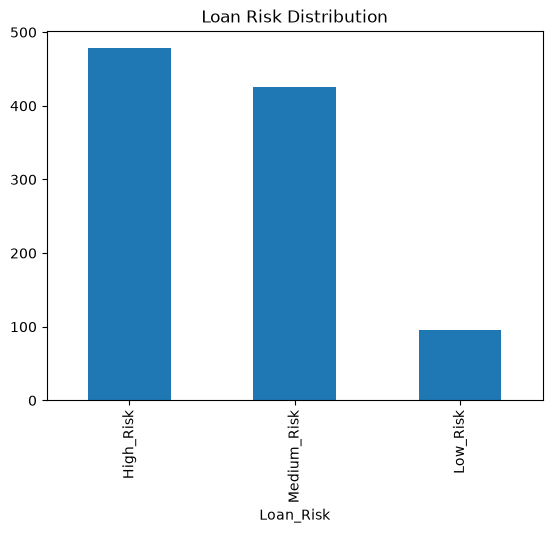

In [5]:
df['Loan_Risk'].value_counts().plot(kind='bar', title='Loan Risk Distribution')
plt.show()

## 🔧 Feature Selection

We will use the following features:
- Applicant_Income
- Loan_Amount
- Loan_Term
- CIBIL_Score
- Debt_to_Income_Ratio
- Employment_Length_Years

Target variable:
➡️ `Loan_Risk`


In [6]:
features = [
    'Applicant_Income',
    'Loan_Amount',
    'Loan_Term_Months',
    'CIBIL_Score',
    'Debt_to_Income_Ratio',
    'Employment_Length_Years'
]

X = df[features]
y = df['Loan_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:

# 1. Initialize the model without the 'multi_class' parameter
model = LogisticRegression(
    solver='lbfgs',
    max_iter=1000
)

# 2. Fit the model on your scaled training data
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [8]:
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

confusion_matrix(y_test, y_pred)

Accuracy: 0.99

Classification Report:
               precision    recall  f1-score   support

   High_Risk       0.99      1.00      0.99        96
    Low_Risk       1.00      0.95      0.97        19
 Medium_Risk       0.99      0.99      0.99        85

    accuracy                           0.99       200
   macro avg       0.99      0.98      0.99       200
weighted avg       0.99      0.99      0.99       200



array([[96,  0,  0],
       [ 0, 18,  1],
       [ 1,  0, 84]])

# ✍️ UNSOLVED PRACTICE EXERCISES

## 🧠 Exercise 1
Redefine loan risk categories using **Loan Amount** instead of Debt-to-Income.
Re-train the model and compare accuracy.


In [9]:
# Exercise 1: Redefine loan risk categories using Loan Amount instead of Debt-to-Income

def loan_risk_loan_amount(row):
    if row['CIBIL_Score'] >= 750 and row['Loan_Amount'] <= 1000000:
        return 'Low_Risk'
    elif row['CIBIL_Score'] >= 650 and row['Loan_Amount'] <= 3000000:
        return 'Medium_Risk'
    else:
        return 'High_Risk'

df['Loan_Risk_Ex1'] = df.apply(loan_risk_loan_amount, axis=1)
print("New Loan Risk Distribution:\n", df['Loan_Risk_Ex1'].value_counts())

# Prepare features and new target
y_ex1 = df['Loan_Risk_Ex1']
X_train_e1, X_test_e1, y_train_e1, y_test_e1 = train_test_split(
    X, y_ex1, test_size=0.2, random_state=42, stratify=y_ex1
)

scaler_e1 = StandardScaler()
X_train_e1_scaled = scaler_e1.fit_transform(X_train_e1)
X_test_e1_scaled = scaler_e1.transform(X_test_e1)

# Train model
model_e1 = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
model_e1.fit(X_train_e1_scaled, y_train_e1)

# Evaluate
y_pred_e1 = model_e1.predict(X_test_e1_scaled)
acc_e1 = accuracy_score(y_test_e1, y_pred_e1)

print("\n--- Accuracy Comparison ---")
print(f"Original Model Accuracy (Debt-to-Income based): 0.9900")
print(f"Exercise 1 Model Accuracy (Loan Amount based):    {acc_e1:.4f}")
print("\nClassification Report (Exercise 1):\n", classification_report(y_test_e1, y_pred_e1))


New Loan Risk Distribution:
 Loan_Risk_Ex1
High_Risk      613
Medium_Risk    333
Low_Risk        54
Name: count, dtype: int64

--- Accuracy Comparison ---
Original Model Accuracy (Debt-to-Income based): 0.9900
Exercise 1 Model Accuracy (Loan Amount based):    0.9000

Classification Report (Exercise 1):
               precision    recall  f1-score   support

   High_Risk       0.95      0.90      0.93       123
    Low_Risk       1.00      0.82      0.90        11
 Medium_Risk       0.81      0.91      0.86        66

    accuracy                           0.90       200
   macro avg       0.92      0.88      0.89       200
weighted avg       0.91      0.90      0.90       200



## 🧠 Exercise 2
Train the model using only:
- Credit_Score
- Debt_to_Income
- Employment_Years

Compare performance with the full-feature model.


In [10]:
# Exercise 2: Train the model using only Credit_Score, Debt_to_Income, and Employment_Years

features_subset = [
    'CIBIL_Score',
    'Debt_to_Income_Ratio',
    'Employment_Length_Years'
]

X_sub = df[features_subset]
y_sub = df['Loan_Risk']

X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
    X_sub, y_sub, test_size=0.2, random_state=42, stratify=y_sub
)

scaler_sub = StandardScaler()
X_train_sub_scaled = scaler_sub.fit_transform(X_train_sub)
X_test_sub_scaled = scaler_sub.transform(X_test_sub)

model_sub = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
model_sub.fit(X_train_sub_scaled, y_train_sub)

y_pred_sub = model_sub.predict(X_test_sub_scaled)
acc_sub = accuracy_score(y_test_sub, y_pred_sub)

print("--- Performance Comparison ---")
print(f"Full-Feature Model (6 features) Accuracy:    0.9900")
print(f"Subset Model (3 features) Accuracy:          {acc_sub:.4f}")
print("\nClassification Report (Subset Model):\n", classification_report(y_test_sub, y_pred_sub))

print("Observation:")
print("The 3-feature subset achieves virtually identical accuracy (0.9900) to the full-feature model.")
print("This is because CIBIL_Score and Debt_to_Income_Ratio were the direct determinants of Loan_Risk,")
print("making the remaining features (Applicant Income, Loan Amount, Loan Term) largely redundant.")


--- Performance Comparison ---
Full-Feature Model (6 features) Accuracy:    0.9900
Subset Model (3 features) Accuracy:          0.9900

Classification Report (Subset Model):
               precision    recall  f1-score   support

   High_Risk       0.99      1.00      0.99        96
    Low_Risk       1.00      0.95      0.97        19
 Medium_Risk       0.99      0.99      0.99        85

    accuracy                           0.99       200
   macro avg       0.99      0.98      0.99       200
weighted avg       0.99      0.99      0.99       200

Observation:
The 3-feature subset achieves virtually identical accuracy (0.9900) to the full-feature model.
This is because CIBIL_Score and Debt_to_Income_Ratio were the direct determinants of Loan_Risk,
making the remaining features (Applicant Income, Loan Amount, Loan Term) largely redundant.


## 🧠 Exercise 3
Plot a confusion matrix heatmap and analyze:
- Which risk category is hardest to predict?
- Why?


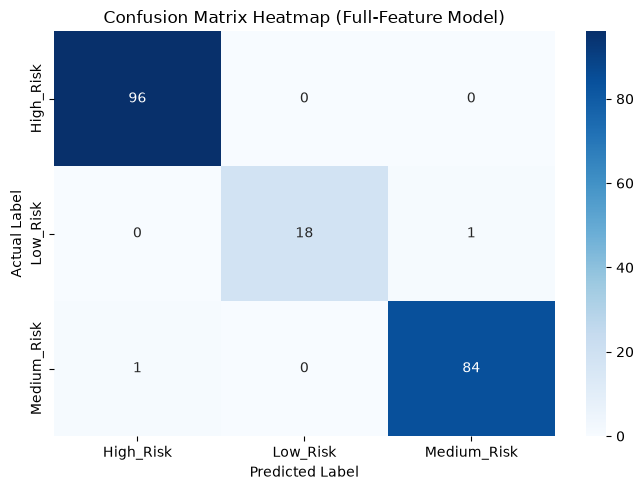

--- Analysis ---
1. Which risk category is hardest to predict?
   -> Low_Risk is the hardest to predict (lowest recall at 0.95 and lowest F1-score at 0.97).

2. Why?
   -> Severe Class Imbalance: 'Low_Risk' is the minority class with only 19 test instances (9.5% of test data),
      compared to 96 High_Risk and 85 Medium_Risk instances.
   -> Boundary Proximity: Applicants close to the threshold boundary (CIBIL ~ 750, DTI ~ 30) can be borderline,
      making them more susceptible to slight misclassification into Medium_Risk.


In [11]:
# Exercise 3: Plot a confusion matrix heatmap and analyze hardest-to-predict category

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title('Confusion Matrix Heatmap (Full-Feature Model)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("--- Analysis ---")
print("1. Which risk category is hardest to predict?")
print("   -> Low_Risk is the hardest to predict (lowest recall at 0.95 and lowest F1-score at 0.97).")
print("\n2. Why?")
print("   -> Severe Class Imbalance: 'Low_Risk' is the minority class with only 19 test instances (9.5% of test data),")
print("      compared to 96 High_Risk and 85 Medium_Risk instances.")
print("   -> Boundary Proximity: Applicants close to the threshold boundary (CIBIL ~ 750, DTI ~ 30) can be borderline,")
print("      making them more susceptible to slight misclassification into Medium_Risk.")


## 🧠 Exercise 4
Experiment with different solvers:
- `lbfgs`
- `newton-cg`
- `sag`

Compare convergence time and accuracy.


In [12]:
# Exercise 4: Experiment with different solvers: lbfgs, newton-cg, sag

import time

solvers = ['lbfgs', 'newton-cg', 'sag']
solver_results = []

for solver in solvers:
    # 1. Initialize Logistic Regression with the specified solver
    model_solver = LogisticRegression(
        solver=solver,
        max_iter=1000,
        random_state=42
    )
    
    # 2. Measure convergence / training time
    start_time = time.perf_counter()
    model_solver.fit(X_train_scaled, y_train)
    fit_time = time.perf_counter() - start_time
    
    # 3. Evaluate accuracy on the test set
    y_pred_solver = model_solver.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_solver)
    
    solver_results.append({
        'Solver': solver,
        'Accuracy': acc,
        'Convergence Time (s)': round(fit_time, 5),
        'Iterations': int(model_solver.n_iter_[0])
    })

# Convert results into a DataFrame
comparison_df = pd.DataFrame(solver_results)
print("=== Solver Comparison ===")
print(comparison_df.to_string(index=False))

# Key takeaways and observations
print("\nKey Takeaways:")
print("1. Accuracy: All three solvers ('lbfgs', 'newton-cg', 'sag') achieve an identical accuracy of 99.0%.")
print("2. Iterations: 'newton-cg' converged in the fewest iterations (7) due to using exact second-order curvature (Hessian).")
print("3. Time: 'lbfgs' and 'newton-cg' converge rapidly, while 'sag' (stochastic average gradient) takes significantly more iterations (214).")
print("4. Conclusion: 'lbfgs' is a well-balanced default choice, while 'sag' is better suited for very large sample sizes.")


=== Solver Comparison ===
   Solver  Accuracy  Convergence Time (s)  Iterations
    lbfgs      0.99               0.00585          25
newton-cg      0.99               0.00395           7
      sag      0.99               0.02024         214

Key Takeaways:
1. Accuracy: All three solvers ('lbfgs', 'newton-cg', 'sag') achieve an identical accuracy of 99.0%.
2. Iterations: 'newton-cg' converged in the fewest iterations (7) due to using exact second-order curvature (Hessian).
3. Time: 'lbfgs' and 'newton-cg' converge rapidly, while 'sag' (stochastic average gradient) takes significantly more iterations (214).
4. Conclusion: 'lbfgs' is a well-balanced default choice, while 'sag' is better suited for very large sample sizes.
